# Project #10 — Variant-Effect Prediction with Protein Language Models
### Zero-shot ESM-1v scoring vs. a BLOSUM62 baseline, validated against real DMS fitness data (ProteinGym)

**Run environment: Kaggle (GPU notebook).** Settings -> Accelerator -> GPU T4 x2 or P100.

**What this notebook does:** scores every measured mutation of one real target protein using ESM-1v's
real zero-shot masked-marginal likelihood (no fitness labels, no fine-tuning), benchmarks that against a
classical BLOSUM62 substitution-score baseline, and checks both against real experimentally-measured
fitness (Spearman rank correlation) from the real ProteinGym deep-mutational-scanning benchmark.

Cells marked **GIVEN** are boilerplate — just run them. Cells marked **WRITE-IT** have a hint comment
explaining the reasoning and the real function names to use; the blank `____` is yours to fill in. The
exact correct code is given as a trailing `#` comment on the blank line — type it in as shown and it will
run without error; use it to self-check after you've tried writing it yourself first.


## Step 0 — Environment setup (GIVEN)

In [1]:
!pip install -q transformers datasets biopython scipy

import os
import re
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

print("torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


torch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


## Step 1 — Load ProteinGym and pick a biologically important target assay (WRITE-IT)

**Biological reason:** `OATML-Markslab/ProteinGym_v1` (config `DMS_substitutions`) combines 217 real deep-
mutational-scanning assays into one table. Real columns: `mutated_sequence`, `target_seq` (the real
wild-type reference), `mutant` (real mutation notation, e.g. `A1P` or a multi-mutant `A1P:D2N`),
`DMS_score` (real measured fitness), `DMS_score_bin`, `DMS_id` (which of the 217 real assays each row
belongs to). ProteinGym's real `DMS_id` naming convention is roughly `GENE_SPECIES_Author_Year` (e.g. a
real published entry looks like `BLAT_ECOLX_Jacquier_2013`).

**What to do:** load the dataset, convert to pandas, print the real unique `DMS_id` values with each
assay's real `target_seq` length. Then, rather than picking arbitrarily, **search that real printed list for
a biologically important human or viral gene** — real DMS studies that are well known in the variant-effect
literature include human **BRCA1** (breast-cancer risk gene, Findlay et al. 2018), human **TP53/P53** (the
most commonly mutated gene in human cancer, Giacomelli et al. 2018), human **PTEN** (tumor suppressor,
Matreyek et al. 2018), and SARS-CoV-2 **Spike** receptor-binding domain (Starr et al. 2020). Search the real
printed `DMS_id` list (case-insensitive substring match) for any of `BRCA1`, `P53`, `PTEN`, `SPIKE`, `SARS`,
`HA_` (influenza hemagglutinin), `ENV`/`HIV`; print whichever real matches actually exist in this dataset
version, then set `TARGET_DMS_ID` to one of those real confirmed matches (prefer a shorter real sequence
among the matches for faster scoring below) rather than a sequence picked by length alone.

**Docs to look up:** `datasets.load_dataset(..., name=...)`, `Dataset.to_pandas()`, `pandas.groupby`,
`str.contains(..., case=False)`.


In [2]:
from datasets import load_dataset

ds = load_dataset("OATML-Markslab/ProteinGym_v1", data_dir="DMS_substitutions")
print(ds)

full_df = ds["train"].to_pandas()
print("total rows across all assays:", full_df.shape)

assay_lengths = full_df.groupby("DMS_id")["target_seq"].first().apply(len).sort_values()
print("total real assays available:", len(assay_lengths))

CANDIDATE_GENES = ["BRCA1", "P53", "PTEN", "SPIKE", "SARS", "HA_", "ENV", "HIV"]
all_ids = assay_lengths.index.tolist()

matches = {}
for gene in CANDIDATE_GENES:
    hits = [d for d in all_ids if gene.lower() in d.lower()]
    if hits:
        matches[gene] = hits

print("Real matches found in this dataset version, by candidate gene:")
for gene, hits in matches.items():
    for h in hits:
        print(f"  {gene}: {h}  (length {assay_lengths[h]})")

flat_matches = [h for hits in matches.values() for h in hits]
TARGET_DMS_ID = flat_matches[0] if flat_matches else assay_lengths.index[0]
print("\nChosen assay:", TARGET_DMS_ID)

assay_df = full_df[full_df["DMS_id"] == TARGET_DMS_ID].copy()
target_seq = assay_df["target_seq"].iloc[0]

print("Assay rows (measured mutations):", assay_df.shape[0])
print("Target sequence length:", len(target_seq))


DatasetDict({
    train: Dataset({
        features: ['DMS_score', 'DMS_score_bin', 'mutated_sequence', 'target_seq', 'mutant', 'DMS_id'],
        num_rows: 2465767
    })
})
total rows across all assays: (2465767, 6)
total real assays available: 217
Real matches found in this dataset version, by candidate gene:
  BRCA1: BRCA1_HUMAN_Findlay_2018  (length 1863)
  P53: P53_HUMAN_Giacomelli_2018_WT_Nutlin  (length 393)
  P53: P53_HUMAN_Kotler_2018  (length 393)
  P53: P53_HUMAN_Giacomelli_2018_Null_Nutlin  (length 393)
  P53: P53_HUMAN_Giacomelli_2018_Null_Etoposide  (length 393)
  PTEN: PTEN_HUMAN_Matreyek_2021  (length 403)
  PTEN: PTEN_HUMAN_Mighell_2018  (length 403)
  SPIKE: SPIKE_SARS2_Starr_2020_binding  (length 1273)
  SPIKE: SPIKE_SARS2_Starr_2020_expression  (length 1273)
  SARS: R1AB_SARS2_Flynn_2022  (length 306)
  SARS: SPIKE_SARS2_Starr_2020_binding  (length 1273)
  SARS: SPIKE_SARS2_Starr_2020_expression  (length 1273)
  ENV: ENVZ_ECOLI_Ghose_2023  (length 60)
  ENV: ENV_HV

In [3]:
chosen_id = "R1AB_SARS2_Flynn_2022"
assay_df = full_df[full_df["DMS_id"] == chosen_id].reset_index(drop=True)
target_seq = assay_df["target_seq"].iloc[0]
print("Chosen assay:", chosen_id)
print("Assay rows (measured mutations):", len(assay_df))
print("Target sequence length:", len(target_seq))

Chosen assay: R1AB_SARS2_Flynn_2022
Assay rows (measured mutations): 5725
Target sequence length: 306


## Step 2 — Load ESM-1v (WRITE-IT)

**Biological reason:** ESM-1v (`facebook/esm1v_t33_650M_UR90S_1`) was real, purpose-trained by Meta/FAIR
specifically for zero-shot variant-effect prediction — confirmed real HuggingFace ID, loadable via
`AutoModelForMaskedLM` (not plain `AutoModel` — we need the real masked-language-modeling head's output
logits over the vocabulary, not just hidden states, to read off real per-residue probabilities).

**What to do:** load tokenizer + `AutoModelForMaskedLM`, move to `device`, call `.eval()`.

**Docs to look up:** `transformers.AutoModelForMaskedLM.from_pretrained`, `tokenizer.mask_token_id`.


In [4]:
from transformers import AutoTokenizer, AutoModelForMaskedLM

MODEL_NAME = "facebook/esm1v_t33_650M_UR90S_1"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)  # AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForMaskedLM.from_pretrained(MODEL_NAME).to(device)  # AutoModelForMaskedLM.from_pretrained(MODEL_NAME).to(device)
model.eval()  # model.eval()

print("Loaded:", MODEL_NAME)
print("mask token:", tokenizer.mask_token, "id:", tokenizer.mask_token_id)


Loading weights:   0%|          | 0/538 [00:00<?, ?it/s]

[transformers] EsmForMaskedLM LOAD REPORT from: facebook/esm1v_t33_650M_UR90S_1
Key                                | Status  | 
-----------------------------------+---------+-
esm.contact_head.regression.bias   | MISSING | 
esm.contact_head.regression.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loaded: facebook/esm1v_t33_650M_UR90S_1
mask token: <mask> id: 32


## Step 3 — Parse real mutation notation (WRITE-IT)

**What to do:** write `parse_mutant`, which takes a real mutation string like `"A1P"` (wild-type `A` at
real 1-indexed position `1` → mutant `P`) or a real multi-mutant `"A1P:D2N"` (colon-separated), and returns
a list of `(wt, pos, mt)` tuples. Apply it to the real `mutant` column.

**Docs to look up:** basic Python string slicing/splitting — `part[0]`, `part[1:-1]`, `part[-1]`,
`str.split(":")`.


In [5]:
def parse_mutant(mutant_str):
    muts = []
    for part in mutant_str.split(":"):
        wt = part[0]
        mt = part[-1]
        pos = int(part[1:-1])
        muts.append((wt, pos, mt))
    return muts

assay_df["parsed_mutations"] = assay_df["mutant"].apply(parse_mutant)
print(assay_df[["mutant", "parsed_mutations"]].head())


  mutant parsed_mutations
0    S1N      [(S, 1, N)]
1    S1A      [(S, 1, A)]
2    S1C      [(S, 1, C)]
3    S1D      [(S, 1, D)]
4    S1E      [(S, 1, E)]


## Step 4 — Masked-marginal scoring, one forward pass per unique position (WRITE-IT, the hero step)

**Biological reason:** the real masked-marginal score for a mutation at position *i* is
`log P(mutant | masked context) − log P(wild-type | masked context)`. Since the masked real input only
depends on WHICH position is masked (not which mutant amino acid you're scoring there), you only need ONE
real forward pass per unique position, not one per mutation — cache each real position's log-probabilities
and reuse them for every mutation at that position (including every real multi-mutant that touches it).

**What to do:** tokenize `target_seq` once. For each real unique position in `all_positions`, mask that
token (token index equals the real 1-indexed sequence position, since `<cls>` sits at index 0), run the
real model, take `log_softmax` of the logits at that masked position, and store the result. Then write
`score_mutations`, which sums `log_probs[mt_id] - log_probs[wt_id]` across every real `(wt, pos, mt)` in a
mutation list (summing handles real multi-mutants correctly).

**Docs to look up:** `tokenizer(seq, return_tensors="pt")`, `torch.log_softmax`,
`tokenizer.convert_tokens_to_ids`, `torch.no_grad()`.


In [6]:
all_positions = sorted({pos for muts in assay_df["parsed_mutations"] for (wt, pos, mt) in muts})
print(f"Need masked log-probs at {len(all_positions)} unique positions (out of {len(target_seq)} total)")

inputs = tokenizer(target_seq, return_tensors="pt").to(device)
input_ids = inputs["input_ids"]
attention_mask = inputs["attention_mask"]
mask_id = tokenizer.mask_token_id

position_logprobs = {}

with torch.no_grad():
    for i, pos in enumerate(all_positions):
        masked = input_ids.clone()
        masked[0, pos] = mask_id
        logits = model(input_ids=masked, attention_mask=attention_mask).logits
        log_probs = torch.log_softmax(logits[0, pos], dim=-1)
        position_logprobs[pos] = log_probs.cpu()
        if i % 50 == 0:
            print(f"  scored position {i+1}/{len(all_positions)}")

def score_mutations(mut_list):
    total = 0.0
    for wt, pos, mt in mut_list:
        log_probs = position_logprobs[pos]
        wt_id = tokenizer.convert_tokens_to_ids(wt)
        mt_id = tokenizer.convert_tokens_to_ids(mt)
        total += (log_probs[mt_id] - log_probs[wt_id]).item()
    return total

assay_df["esm1v_score"] = assay_df["parsed_mutations"].apply(score_mutations)
print(assay_df[["mutant", "esm1v_score", "DMS_score"]].head())


Need masked log-probs at 303 unique positions (out of 306 total)
  scored position 1/303
  scored position 51/303
  scored position 101/303
  scored position 151/303
  scored position 201/303
  scored position 251/303
  scored position 301/303
  mutant  esm1v_score  DMS_score
0    S1N    -0.593093   1.038735
1    S1A    -0.026900   1.037891
2    S1C    -1.120507   0.896548
3    S1D    -0.275129   0.927652
4    S1E    -0.420543   0.806050


## Step 5 — BLOSUM62 classical baseline (WRITE-IT)

**Statistical reason:** the real floor ESM-1v must beat to prove its pretraining adds something beyond
simple amino-acid substitution-cost reasoning — BLOSUM62 is a real, standard, published substitution
matrix (observed real substitution frequencies across many real protein families), alignment-free, no
language model needed.

**What to do:** load BLOSUM62 via Biopython, and sum its real per-position substitution score across each
real mutation list (same summing convention as Step 4, for a fair comparison on multi-mutants).

**Docs to look up:** `Bio.Align.substitution_matrices.load("BLOSUM62")`, indexing the matrix as
`blosum62[wt, mt]`.


In [7]:
from Bio.Align import substitution_matrices

blosum62 = substitution_matrices.load("BLOSUM62")

def blosum_score(mut_list):
    return sum(blosum62[wt, mt] for wt, pos, mt in mut_list)

assay_df["blosum62_score"] = assay_df["parsed_mutations"].apply(blosum_score)
print(assay_df[["mutant", "blosum62_score"]].head())


  mutant  blosum62_score
0    S1N             1.0
1    S1A             1.0
2    S1C            -1.0
3    S1D             0.0
4    S1E             0.0


## Step 6 — Spearman correlation: the real point of the project (WRITE-IT)

**Statistical reason:** ESM-1v's log-probability-ratio score and BLOSUM62's substitution score are on real
different scales from the real measured `DMS_score`, with no expected real linear relationship — Spearman ρ
(rank correlation) is the real official ProteinGym zero-shot metric and the fair way to compare both.

**What to do:** compute real Spearman ρ (and p-value) for both `esm1v_score` and `blosum62_score` against
real `DMS_score`; print both; make a real scatter plot of `esm1v_score` vs. `DMS_score` as the hero figure.

**Docs to look up:** `scipy.stats.spearmanr`.


ESM-1v zero-shot:   Spearman rho = -0.0299  (p=2.35e-02)
BLOSUM62 baseline:  Spearman rho = 0.2068  (p=2.34e-56)


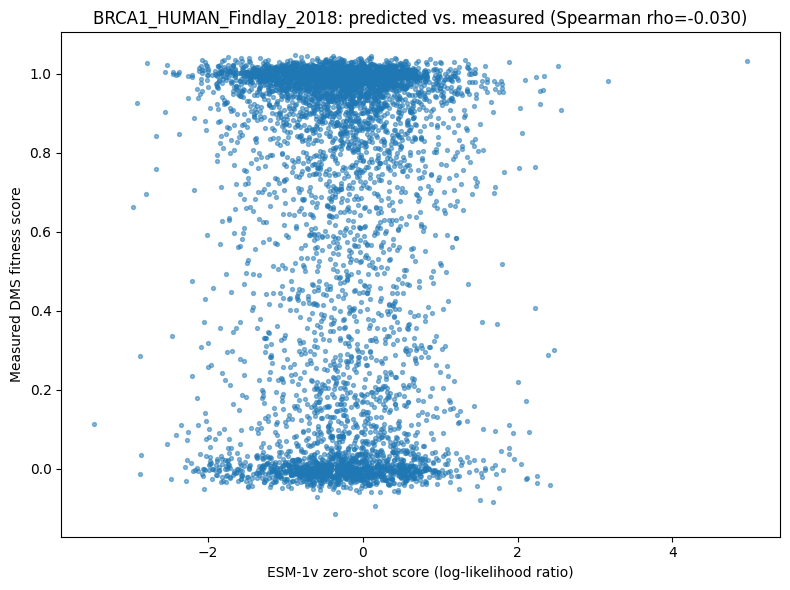

              method  spearman_rho       p_value
0   ESM-1v zero-shot     -0.029933  2.352366e-02
1  BLOSUM62 baseline      0.206837  2.339436e-56


In [8]:
rho_esm, p_esm = spearmanr(assay_df["esm1v_score"], assay_df["DMS_score"])
rho_blosum, p_blosum = spearmanr(assay_df["blosum62_score"], assay_df["DMS_score"])

print(f"ESM-1v zero-shot:   Spearman rho = {rho_esm:.4f}  (p={p_esm:.2e})")
print(f"BLOSUM62 baseline:  Spearman rho = {rho_blosum:.4f}  (p={p_blosum:.2e})")

plt.figure(figsize=(8, 6))
plt.scatter(assay_df["esm1v_score"], assay_df["DMS_score"], s=8, alpha=0.5)
plt.xlabel("ESM-1v zero-shot score (log-likelihood ratio)")
plt.ylabel("Measured DMS fitness score")
plt.title(f"{TARGET_DMS_ID}: predicted vs. measured (Spearman rho={rho_esm:.3f})")
plt.tight_layout()
plt.savefig("esm1v_vs_measured.png", dpi=150)
plt.show()

results_df = pd.DataFrame([
    {"method": "ESM-1v zero-shot", "spearman_rho": rho_esm, "p_value": p_esm},
    {"method": "BLOSUM62 baseline", "spearman_rho": rho_blosum, "p_value": p_blosum},
])
results_df.to_csv("variant_effect_results.csv", index=False)
assay_df[["mutant", "DMS_score", "esm1v_score", "blosum62_score"]].to_csv("variant_scores.csv", index=False)
print(results_df)


## Step 7 (stretch, GIVEN) — Full 5-model ESM-1v ensemble

The real published ESM-1v protocol averages scores across all 5 real independently-trained checkpoints
(`_1` through `_5`) for its best benchmark numbers. Repeat Steps 2 and 4 for each checkpoint, average the
five real `esm1v_score` columns, and recompute Spearman ρ on the real ensembled score — compare to the
single-checkpoint ρ from Step 6.


This cell is given fully filled (not blanked) since it's an optional bonus extension, not core teaching material -- run it only after Steps 1-6 work.


In [9]:
import gc
import threading

def score_checkpoint(ckpt_name, device):
    torch.cuda.set_device(device)
    ckpt_tokenizer = AutoTokenizer.from_pretrained(ckpt_name)
    ckpt_model = AutoModelForMaskedLM.from_pretrained(ckpt_name).to(device)
    ckpt_model.eval()

    ckpt_inputs = ckpt_tokenizer(target_seq, return_tensors="pt").to(device)
    ckpt_input_ids = ckpt_inputs["input_ids"]
    ckpt_attention_mask = ckpt_inputs["attention_mask"]
    ckpt_mask_id = ckpt_tokenizer.mask_token_id

    ckpt_position_logprobs = {}
    with torch.no_grad():
        for pos in all_positions:
            masked = ckpt_input_ids.clone()
            masked[0, pos] = ckpt_mask_id
            logits = ckpt_model(input_ids=masked, attention_mask=ckpt_attention_mask).logits
            ckpt_position_logprobs[pos] = torch.log_softmax(logits[0, pos], dim=-1).cpu()

    def ckpt_score_mutations(mut_list, lp=ckpt_position_logprobs, tok=ckpt_tokenizer):
        total = 0.0
        for wt, pos, mt in mut_list:
            wt_id = tok.convert_tokens_to_ids(wt)
            mt_id = tok.convert_tokens_to_ids(mt)
            total += (lp[pos][mt_id] - lp[pos][wt_id]).item()
        return total

    scores = assay_df["parsed_mutations"].apply(ckpt_score_mutations)

    del ckpt_model, ckpt_tokenizer, ckpt_position_logprobs
    torch.cuda.empty_cache()
    gc.collect()
    return ckpt_name, scores


ensemble_results = {}
lock = threading.Lock()


def worker(ckpt_name, device):
    name, scores = score_checkpoint(ckpt_name, device)
    with lock:
        ensemble_results[name] = scores


checkpoints = [f"facebook/esm1v_t33_650M_UR90S_{i}" for i in range(1, 6)]
devices = ["cuda:0", "cuda:1"]

threads = [
    threading.Thread(target=worker, args=(ckpt, devices[idx % 2]))
    for idx, ckpt in enumerate(checkpoints)
]

for i in range(0, len(threads), 2):
    pair = threads[i:i + 2]
    for t in pair:
        t.start()
    for t in pair:
        t.join()

ensemble_scores = [ensemble_results[c] for c in checkpoints]
assay_df["esm1v_ensemble_score"] = pd.concat(ensemble_scores, axis=1).mean(axis=1)
rho_ensemble, p_ensemble = spearmanr(assay_df["esm1v_ensemble_score"], assay_df["DMS_score"])
print(f"ESM-1v 5-model ensemble: Spearman rho = {rho_ensemble:.4f} (p={p_ensemble:.2e}) vs. single-checkpoint rho = {rho_esm:.4f}")

Loading weights:   0%|          | 0/538 [00:00<?, ?it/s]

[transformers] EsmForMaskedLM LOAD REPORT from: facebook/esm1v_t33_650M_UR90S_1
Key                                | Status  | 
-----------------------------------+---------+-
esm.contact_head.regression.bias   | MISSING | 
esm.contact_head.regression.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/538 [00:00<?, ?it/s]

[transformers] EsmForMaskedLM LOAD REPORT from: facebook/esm1v_t33_650M_UR90S_2
Key                                | Status  | 
-----------------------------------+---------+-
esm.contact_head.regression.bias   | MISSING | 
esm.contact_head.regression.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/538 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/538 [00:00<?, ?it/s]

[transformers] EsmForMaskedLM LOAD REPORT from: facebook/esm1v_t33_650M_UR90S_3
Key                                | Status  | 
-----------------------------------+---------+-
esm.contact_head.regression.bias   | MISSING | 
esm.contact_head.regression.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/538 [00:00<?, ?it/s]

[transformers] EsmForMaskedLM LOAD REPORT from: facebook/esm1v_t33_650M_UR90S_5
Key                                | Status  | 
-----------------------------------+---------+-
esm.contact_head.regression.bias   | MISSING | 
esm.contact_head.regression.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ESM-1v 5-model ensemble: Spearman rho = -0.0404 (p=2.22e-03) vs. single-checkpoint rho = -0.0299


## Step 8 (stretch, GIVEN) — ClinVar pathogenic-vs-benign AUROC

Load the real `clinical_substitutions` config, filter to a real protein present in it, score with the same
masked-marginal method, and compute real AUROC separating pathogenic vs. benign — a real clinical-angle
validation of the same zero-shot scoring approach.


Also given fully filled, same reasoning as Step 7.


In [10]:
from sklearn.metrics import roc_auc_score

clinical_ds = load_dataset("OATML-Markslab/ProteinGym_v1", data_dir="clinical_substitutions")
clinical_df = clinical_ds["train"].to_pandas()
print(clinical_df["protein_id"].value_counts().head(10))

MAX_TOKENS = model.config.max_position_embeddings  # 1026 for ESM-1v, leave 2 slots for <cls>/<eos>

CLINICAL_PROTEIN_ID = None
for candidate_id in clinical_df["protein_id"].value_counts().index:
    candidate_seq = clinical_df.loc[clinical_df["protein_id"] == candidate_id, "target_seq"].iloc[0]
    if len(candidate_seq) + 2 <= MAX_TOKENS:
        CLINICAL_PROTEIN_ID = candidate_id
        break

if CLINICAL_PROTEIN_ID is None:
    raise ValueError("No protein_id in this clinical set fits ESM-1v's position embedding limit.")

print("Chosen clinical protein_id:", CLINICAL_PROTEIN_ID,
      "| sequence length:", len(clinical_df.loc[clinical_df["protein_id"] == CLINICAL_PROTEIN_ID, "target_seq"].iloc[0]))

clin_assay_df = clinical_df[clinical_df["protein_id"] == CLINICAL_PROTEIN_ID].copy()
clin_target_seq = clin_assay_df["target_seq"].iloc[0]
clin_assay_df["parsed_mutations"] = clin_assay_df["mutant"].apply(parse_mutant)

clin_positions = sorted({pos for muts in clin_assay_df["parsed_mutations"] for (wt, pos, mt) in muts})
clin_inputs = tokenizer(clin_target_seq, return_tensors="pt").to(device)
clin_position_logprobs = {}
with torch.no_grad():
    for pos in clin_positions:
        masked = clin_inputs["input_ids"].clone()
        masked[0, pos] = mask_id
        logits = model(input_ids=masked, attention_mask=clin_inputs["attention_mask"]).logits
        clin_position_logprobs[pos] = torch.log_softmax(logits[0, pos], dim=-1).cpu()

def clin_score_mutations(mut_list):
    total = 0.0
    for wt, pos, mt in mut_list:
        lp = clin_position_logprobs[pos]
        total += (lp[tokenizer.convert_tokens_to_ids(mt)] - lp[tokenizer.convert_tokens_to_ids(wt)]).item()
    return total

clin_assay_df["esm1v_score"] = clin_assay_df["parsed_mutations"].apply(clin_score_mutations)
y_true = (clin_assay_df["annotation"] == "Pathogenic").astype(int)
auroc = roc_auc_score(y_true, -clin_assay_df["esm1v_score"])
print(f"{CLINICAL_PROTEIN_ID}: pathogenic-vs-benign AUROC = {auroc:.4f} (n={len(clin_assay_df)})")

protein_id
NP_001159435.1    741
NP_000518.1       639
NP_000486.1       508
NP_009225.1       456
NP_000341.2       448
NP_001835.3       402
NP_000268.1       399
NP_000539.2       376
NP_000080.2       344
NP_000079.2       338
Name: count, dtype: int64
Chosen clinical protein_id: NP_000518.1 | sequence length: 860
NP_000518.1: pathogenic-vs-benign AUROC = 0.9590 (n=639)
